# Photoreceptor segmentation using [napari](https://napari.org/) and [cellpose](https://cellpose-napari.readthedocs.io/en/latest/index.html)

### Basic usage:
```python
viewer = napari.Viewer()
nbscreenshot(viewer)
viewer.close()
```

example notebooks [here](https://github.com/sofroniewn/napari-training-course/blob/master/lessons/)

In [2]:
# !mamba install -c conda-forge devbio-napari --yes
# !jupyter labextension list
# !mamba install -c conda-forge cellpose-napari --yes
# from cellpose import models

ModuleNotFoundError: No module named 'cellpose'

In [1]:
# image analysis
import napari
from magicgui import magicgui
from enum import Enum
import cellpose_napari
import cellpose
from cellpose import models
from tifffile import imread
import napari_nikon_nd2
from skimage.io import imread
from magicgui import magicgui
# python basics and plotting
import numpy as np
import pandas as pd
import math
from scipy import ndimage
from scipy.stats import kruskal
from scipy.stats import zscore
from scipy.stats import sem
import scikit_posthocs
import scipy.spatial
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import svgutils
from svgutils.compose import *
# system interaction
import os.path
import time, sys, warnings, re
from tqdm.notebook import tqdm, trange
import importlib
import ipywidgets
from IPython.display import display
# lab brews
from plotParams import *
from lloyd import *


def getFileList(dirData,gene,fileNameMatch,addDetails=''):
   fileList = sorted([f for f in os.listdir(dirData) if not f.startswith('.')]) # get all the files in the data directory (excluding system files) and sort them alphabatically
   fileList = ([f for f in fileList if gene in f]) # select files that match the gene of interest
   fileList = ([f for f in fileList if any([s in f for s in fileNameMatch])]) # only keep relevant files
   if (addDetails=='path'):
      fileList = (['# filePath = \'' + f for f in fileList]) # add text before each file
      fileList = list(map(lambda st: str.replace(st, '.nd2', '\'; gene = \'' + gene + '\'; '), fileList)) #remove file extension (.nd2) and add text after each file
   elif (addDetails=='list'):
      fileList = (['\'' + f for f in fileList]) # add text before each file
      fileList = list(map(lambda st: str.replace(st, '.nd2', '\','), fileList)) #remove file extension (.nd2) and add text after each file
   else:
      fileList = list(map(lambda st: str.replace(st, '.nd2', ''), fileList)) #remove file extension (.nd2) and add text after each file
   return fileList


pBGMenu = ipywidgets.Dropdown(options=['Light', 'Dark'],value='Dark',disabled=False, layout=ipywidgets.Layout(width='20%', height='40px'))
pBGLabel = ipywidgets.widgets.Label('Select plotting style', layout=ipywidgets.Layout(width='20%', height='30px'))
pBG = ipywidgets.widgets.VBox([pBGLabel,pBGMenu])
pBG

In [2]:
applyPlotStyle(pBGMenu.value)
viewer = napari.Viewer()

Plotting style is Dark


In [13]:
viewer = napari.Viewer()

In [9]:
        viewer.close()

***
# Index <a id='Index'></a>
***
- [define directories](#dirDef)
- [Extraction of z planes for analysis](#zExtract)
- [Segmentation with cellpose](#cellSeg)
- [Manual correction of segmentation](#manualCuration)
- [Create thumbnails _WIP_](#thumbnails)
- [Quantification](#quantification)

***
## Define directories<a id='dirDefdirDef'>∮</a>
***
[Back to Index](#Index)

In [4]:
# define where all the imaging data is stored
dirData = 'Z:/AxR/20260610_4MO_Tbx2aAdult_Cryosections_tdT_m2G/'
# define where all the analysis files should be stored
# subdirectories for each gene and transgenic lines need to be manually made first
dirAnalysis =  "Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/"
# dirAnalysis =  "Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/"

# # define where all the imaging data is stored
# dirData = 'D:/Imaging/0250202_2bhetinx_s2C_m2G/'
# # define where all the analysis files should be stored
# # subdirectories for each gene and transgenic lines need to be manually made first
# dirAnalysis = 'D:/Analysis/20250202_Tbx2bhetinx_m2Gs2C/m2Gs2C/'

In [8]:
gene = '' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
# gene = 'lhx1a' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
fileNameMatch = ['003'] # characters in filenames that define zoom-in files
# fileNameMatch = ['004','008'] # characters in filenames that define zoom-in files

# get a list with all the relevant files
print(*getFileList(dirData,gene,fileNameMatch,addDetails='path'), sep = "\n") #display the file list for copy and paste below

# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L01_S01_003'; gene = ''; 
# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L01_S01_003_Denoised'; gene = ''; 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_003'; gene = ''; 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_003_Denoised'; gene = ''; 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S02_003'; gene = ''; 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S02_003_Denoised'; gene = ''; 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_003'; gene = ''; 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_003_Denoised'; gene = ''; 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_003_Denoised_mip'; gene = ''; 


***
## Extract layers from z-stacks<a id='zExtract'>∮</a>
> Open z-stack &rarr; Pick limits in z for Maximum-Intensity Projection (_MIP_) &rarr; save MIPs &rarr; Ensure image was located in central retina
***
[Back to Index](#Index)

In [12]:
# clear viewer if needed
viewer.layers.select_all()
viewer.layers.remove_selected()

In [20]:
# clear viewer before any loading
viewer.layers.select_all()
viewer.layers.remove_selected()

# open files one by one (by commenting and uncommenting each one)

## FUCKKKKKK I OVERWROTE THE JUPYTER NOTEBOOK THAT SAVED ALL MY ZLIMS, AND NUMBERS I QUANTIFIED - LUCKILY ALL ANALYSIS WAS SAVED TO THE NAS - BUT THATS GOING TO BE ABITCH TO REDO ALL OF THAT, 



# Zoom Out [001] 
# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L01_S01_001_mip_stitched'; gene = 'mip_stitched'; #HET 
# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L02_S01_001_mip_stitched'; gene = 'mip_stitched'; #HET
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched'; gene = 'mip_stitched'; #KO
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_001_mip_stitched'; gene = 'mip_stitched'; #KO


#Dorsal zoom in [002/003] - see imaging notes 

# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L01_S01_002'; gene = ''; #dorsal het
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_002'; gene = ''; #dorsal KO 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_003'; gene = ''; #dorsal KO (example same slice)
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S02_002'; gene = ''; #dorsal KO (Example diff slice)
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S02_003'; gene = ''; #dorsal KO (example same slice)
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_002'; gene = ''; #dorsal KO (diff animal)

# Ventral Cones [003/004] - see imaging notes 
# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L01_S01_003'; gene = ''; #ventral het 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_004'; gene = ''; 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_003'; gene = ''; #ventral KO - diff animal
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_004'; gene = ''; #ventral KO -  (example same slice)




layerNames = ['M', 'S','PNA', 'N']
# layerNames = ['M', 'L', 'PNA']
# layerNames = ['M', 'L', 'N']
# layerNames = ['N', 'U']

# create subdirectory for analysis output
dirOut = dirAnalysis + gene + '/' + filePath + '/'
if (os.path.isdir(dirOut)==False):
   os.mkdir(dirOut)
   print('Created output directory')

print('Canvas cleared. Loading data...\n\n')

# load whole stack to figure out best z-planes for cellpose
viewer.open((dirData+filePath + '.nd2'), plugin='napari-nikon-nd2')
viewer.layers.remove(viewer.layers[len(viewer.layers)-1]) # remove transmitted detector image
viewer.layers.select_next();
if len(viewer.layers)==2: #no DAPI
   nChannels = 2
   viewer.layers[0].colormap = 'cyan'
   viewer.layers[0].name = layerNames[0]
   viewer.layers[1].colormap = 'magenta'
   viewer.layers[1].name = layerNames[1]
elif len(viewer.layers) == 3:  # M, L, and PNA
    nChannels = 3
    viewer.layers[0].colormap = "green"
    viewer.layers[0].name = "M"
    viewer.layers[0].opacity = 0.99
    viewer.layers[1].colormap = "magenta"
    viewer.layers[1].name = "S"
    viewer.layers[2].colormap = "bop orange"
    viewer.layers[2].name = "PNA"
# elif len(viewer.layers)==3: #DAPI
#    nChannels = 3
#    viewer.layers[0].colormap = 'green'
#    viewer.layers[0].name = 'M'
#    viewer.layers[0].opacity = 0.99
#    viewer.layers[1].colormap = 'magenta'
#    viewer.layers[1].name = layerNames[0]
#    viewer.layers[2].colormap = 'bop orange'
#    viewer.layers[2].name = layerNames[1]
#    layerNames.append('PNA')
elif len(viewer.layers)==4: #DAPI
   nChannels = 4
   viewer.layers[0].colormap = 'gray'
   viewer.layers[0].name = 'N'
   viewer.layers[0].opacity = 0.99
   viewer.layers[1].colormap = 'green'
   viewer.layers[1].name = layerNames[0]
   viewer.layers[2].colormap = 'magenta'
   viewer.layers[2].name = layerNames[1]
   viewer.layers[3].colormap = 'bop orange'
   viewer.layers[3].name = layerNames[2]
   layerNames.append('N')

print('Images loaded!')

Created output directory
Canvas cleared. Loading data...


Images loaded!


In [21]:
# make mips (and remove any previous ones) by defining the z-limits to use
zlims = [2, 3];
if len(viewer.layers)>nChannels:
    for l in viewer.layers[nChannels:]:
      viewer.layers.remove(l)

for l in viewer.layers[0:nChannels]:
    l.visible = False
#     viewer.layers.remove(l.name + '_mip')
    viewer.add_image(l.data[zlims[0]:zlims[1]].max(axis=0), blending='additive', colormap = l.colormap, name = l.name + "_mip")

In [22]:
# SAVE in folder for batch cellpose analysis (when mips look good)
for name in layerNames:
   l = viewer.layers[name + '_mip']; l.save(dirOut + l.name + '.tiff')
print('MIP layers saved for ' + filePath)

KeyError: "'N_mip' is not in list"

## Load Stitched Cryoimages Into Napari and save as TIFF 
- Stitched mips of the cryosections do not load in napari viewer like normal ND2 files. Need to save them as TIFF in elements or in FIJI first before starting analysis. 
- Save Tiff in FIJI and them import into Napari to draw ROI

## Open stitched Cryosection into Napari

In [54]:
import os
import shutil
import tempfile
from pathlib import Path
import tifffile
import numpy as np

# Clear the Napari viewer
viewer.layers.select_all()
viewer.layers.remove_selected()


dirData = 'Z:/AxR/20260610_4MO_Tbx2aAdult_Cryosections_tdT_m2G/'
dirAnalysis =  "Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/"


## All zoom out slices analyzed

## Zoom Out [001] 
# filePath = '20260610_0yr4mo_tbx2aKO_m2G_s2C_Cryo_L01_S01_001_mip_stitched'; gene = 'mip_stitched'; 
# filePath = '20260610_0yr4mo_tbx2aKO_m2G_s2C_Cryo_L01_S04_001_mip_stitched'; gene = 'mip_stitched'; 
# filePath = '20260610_0yr4mo_tbx2aKO_m2G_s2C_Cryo_L02_S01_001mip_stitched'; gene = 'mip_stitched'; 
# filePath = '20260610_4Mo_Tbx2aHET_m2G_s2C_Cry_L02_S01_001_mip_stitched'; gene = 'mip_stitched'; 

#don't use for replicate in analysis (same animal different slice) 

# Look for either TIFF extension in dirData
candidate_paths = [
    Path(dirData) / f'{filePath}.tif',
    Path(dirData) / f'{filePath}.tiff',
]
mip_path = next((p for p in candidate_paths if p.is_file()), None)

if mip_path is None:
    raise FileNotFoundError(
        'Could not find the TIFF. Checked:\n' +
        '\n'.join(str(p) for p in candidate_paths)
    )

print(f'Loading stitched MIP:\n{mip_path}')

# Read the TIFF directly. This avoids Napari's reader and also avoids
# Windows mapped-drive read errors that can occur with large TIFF files.
try:
    mip_data = tifffile.imread(str(mip_path))
except OSError:
    # If Z: is a mapped/network drive, copy the TIFF locally and retry.
    local_path = Path(tempfile.gettempdir()) / mip_path.name
    print(f'Copying TIFF locally and retrying:\n{local_path}')
    shutil.copy2(str(mip_path), str(local_path))
    mip_data = tifffile.imread(str(local_path))

# Inspect the TIFF dimensions before adding it.
print(f'TIFF shape: {mip_data.shape}')

# Set this to the axis containing channels:
# (C, Y, X) -> 0; (Y, X, C) -> 2.
channel_axis = 0

# Your TIFF shape is (5, 9011, 9011), so the first axis contains 5 image planes.
# Use four biological names plus a generic name for the fifth plane until you
# confirm what that plane represents.
# mip_layer_names = ['N', 'R', 'U', 'PNA', 'TD']
# mip_layer_names = ['N', 'M', 'S', 'PNA', 'TD']
mip_layer_names = ['M', 'L', 'PNA', 'TD']
colormaps = ['green', 'magenta', 'bop orange', 'gray']

# Split every plane along the channel axis into its own Napari layer.
if mip_data.ndim == 3:
    if channel_axis == 0:
        channel_data = mip_data
    else:
        channel_data = mip_data.transpose(
            channel_axis,
            *[i for i in range(mip_data.ndim) if i != channel_axis]
        )

    n_channels = channel_data.shape[0]
    new_layers = []

    for i, channel in enumerate(channel_data):
        layer_name = (
            mip_layer_names[i]
            if i < len(mip_layer_names)
            else f'channel_{i + 1}'
        )
        cmap = colormaps[i] if i < len(colormaps) else 'gray'

        # Set display limits from the nonzero intensity distribution.
        # This changes only how Napari displays the image, not the data used
        # later for measurements or analysis.
        nonzero = channel[channel > 0]
        if nonzero.size > 0:
            low, high = np.percentile(nonzero, [1, 99.8])
        else:
            low, high = np.percentile(channel, [1, 99.8])

        if low >= high:
            low = float(channel.min())
            high = float(channel.max())

        layer = viewer.add_image(
            channel,
            name=layer_name,
            colormap=cmap,
            contrast_limits=(float(low), float(high)),
            gamma=1,
            blending='additive',
            interpolation='nearest',
        )
        new_layers.append(layer)
        print(f'{layer_name}: contrast limits = ({low:.2f}, {high:.2f})')
else:
    raise ValueError(
        f'Expected a 3D TIFF with a channel axis, but got shape {mip_data.shape}'
    )

print(f'Images loaded! Layers: {[layer.name for layer in new_layers]}')


Loading stitched MIP:
Z:\AxR\20260610_4MO_Tbx2aAdult_Cryosections_tdT_m2G\20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched.tif
TIFF shape: (4, 7341, 9106)


C:\Users\Carin\AppData\Local\Temp\ipykernel_41772\2403957023.py:99: DeprecationWarning: Argument interpolation is deprecated, please use interpolation2d instead. It will be removed in 0.6.0.
  layer = viewer.add_image(


M: contrast limits = (171.00, 1289.00)


C:\Users\Carin\AppData\Local\Temp\ipykernel_41772\2403957023.py:99: DeprecationWarning: Argument interpolation is deprecated, please use interpolation2d instead. It will be removed in 0.6.0.
  layer = viewer.add_image(


L: contrast limits = (173.00, 2355.00)


C:\Users\Carin\AppData\Local\Temp\ipykernel_41772\2403957023.py:99: DeprecationWarning: Argument interpolation is deprecated, please use interpolation2d instead. It will be removed in 0.6.0.
  layer = viewer.add_image(


PNA: contrast limits = (190.00, 2799.00)
TD: contrast limits = (89.00, 1256.00)
Images loaded! Layers: ['M', 'L', 'PNA', 'TD']


C:\Users\Carin\AppData\Local\Temp\ipykernel_41772\2403957023.py:99: DeprecationWarning: Argument interpolation is deprecated, please use interpolation2d instead. It will be removed in 0.6.0.
  layer = viewer.add_image(


---
## Save Each Layer and add _roa_ layer - Paint around 
> Make sure to manually make _roa_ (region of analysis) label
-  Use a Paintbrush and outline the PR layer inlcuding the tallest subtype from the combination imaged. 

### Save loaded layers as separate TIFF Files and draw your ROI

In [55]:
import os
import re
import shutil
import tempfile
import numpy as np
import tifffile
from qtpy.QtWidgets import QPushButton, QWidget, QVBoxLayout, QLabel

dirData = 'Z:/AxR/20260610_4MO_Tbx2aAdult_Cryosections_tdT_m2G/'
dirAnalysis =  "Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/"

# Use as replicate for analysis - Zoom Out [001] 
# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L01_S01_001_mip_stitched'; gene = 'mip_stitched'; #Great example - optic nerve included (Perhaps for the example zoom out picture)
# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L02_S01_001_mip_stitched'; gene = 'mip_stitched'; #looks good for the plot
filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched'; gene = 'mip_stitched'; #EHHH okay 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_001_mip_stitched'; gene = 'mip_stitched';  

analysis_dir = os.path.join(dirAnalysis, filePath)
os.makedirs(analysis_dir, exist_ok=True)
print(f'Analysis folder: {analysis_dir}')


def save_tiff_to_analysis(data, output_path):
    """Write locally first, then copy to the network analysis folder."""
    data = np.ascontiguousarray(np.asarray(data))
    output_path = os.path.abspath(output_path)

    temp_dir = tempfile.gettempdir()
    temp_path = os.path.join(temp_dir, os.path.basename(output_path))

    # Remove an old temporary file if one exists.
    if os.path.exists(temp_path):
        os.remove(temp_path)

    tifffile.imwrite(temp_path, data, bigtiff=True)
    shutil.copyfile(temp_path, output_path)
    os.remove(temp_path)


# Save each loaded image layer using only its channel label.
image_layers = [
    layer for layer in viewer.layers
    if layer.__class__.__name__ == 'Image'
]

if not image_layers:
    raise ValueError('No image layers are loaded in the Napari viewer.')

save_name_map = {
    'N': 'N',
    'R': 'R',
    'U': 'U',
    'PNA': 'PNA',
    'TD': 'TD',
}

for layer in image_layers:
    current_name = layer.name.strip()
    output_label = save_name_map.get(current_name, current_name)
    output_label = re.sub(r'[<>:"/\\|?*]', '_', output_label)
    output_path = os.path.join(analysis_dir, f'{output_label}.tiff')

    save_tiff_to_analysis(layer.data, output_path)
    print(f'Saved {current_name!r} as {output_path}')


# Add or reuse the ROA Labels layer.
reference_data = np.asarray(image_layers[0].data)

if 'roa' in viewer.layers:
    roa_layer = viewer.layers['roa']
else:
    roa_layer = viewer.add_labels(
        np.zeros(reference_data.shape, dtype=np.uint8),
        name='roa'
    )

viewer.layers.selection.active = roa_layer


def save_roa():
    roa_data = np.asarray(viewer.layers['roa'].data)

    if not np.any(roa_data):
        print("The 'roa' layer is empty. Paint the ROA before saving.")
        return

    # Save only as roa.tiff inside the image-specific folder.
    roa_path = os.path.join(analysis_dir, 'roa.tiff')
    save_tiff_to_analysis((roa_data > 0).astype(np.uint8), roa_path)

    print(f'Saved ROA: {roa_path}')
    print(f'ROA pixels: {np.count_nonzero(roa_data)}')


# Remove an older button if the cell is rerun.
if 'roa_save_widget' in globals():
    try:
        viewer.window.remove_dock_widget(roa_save_widget)
    except Exception:
        pass

roa_save_widget = QWidget()
roa_layout = QVBoxLayout()
roa_layout.addWidget(QLabel('Paint the ROA layer, then click SAVE ROA.'))

save_button = QPushButton('SAVE ROA')
save_button.clicked.connect(save_roa)
roa_layout.addWidget(save_button)

roa_save_widget.setLayout(roa_layout)
viewer.window.add_dock_widget(
    roa_save_widget,
    area='right',
    name='ROA tools'
)

print('Image layers saved.')
print("Paint on 'roa', then click SAVE ROA in the ROA tools panel.")


Analysis folder: Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched
Saved 'M' as Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\M.tiff
Saved 'L' as Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\L.tiff
Saved 'PNA' as Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\PNA.tiff
Saved 'TD' as Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\TD.tiff
Image layers saved.
Paint on 'roa', then click SAVE ROA in the ROA tools panel.
Saved ROA: Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\roa.tiff

### Run Cell to re-open roa with layers

In [66]:
from pathlib import Path
import numpy as np

# Select the dataset
filePath = "20240501_2yr5mo_tbx2ahet_m2G_s2C_L02_001_mip_stitched"
gene = "mip_stitched"

# Other datasets, if needed:
# filePath = "20240501_2yr5mo_tbx2ahet_m2G_s2C_L01_001_mip_stitched"
# filePath = "20240501_2yr5mo_tbx2ahet_m2G_s2C_L03_001_mip_stitched"

analysis_dir = (
    Path(r"Z:\Analysis\20240501_Tbx2aHetAdult_s2Cm2G_2yr5mo_CRYO")
    / "mip_stitched"
    / filePath
)

if not analysis_dir.is_dir():
    raise FileNotFoundError(f"Analysis directory not found:\n{analysis_dir}")

# Find ROA files, regardless of capitalization, extension, or location below this folder
roa_candidates = [
    path for path in analysis_dir.rglob("*")
    if path.is_file()
    and "roa" in path.stem.lower()
    and path.suffix.lower() in {".tif", ".tiff"}
]

if not roa_candidates:
    raise FileNotFoundError(
        f"No ROA TIFF file found under:\n{analysis_dir}\n\n"
        "TIFF files found:\n"
        + "\n".join(
            f"  {path}" for path in analysis_dir.rglob("*")
            if path.is_file() and path.suffix.lower() in {".tif", ".tiff"}
        )
    )

if len(roa_candidates) > 1:
    print("Multiple ROA files found; using the first one:")
    for path in roa_candidates:
        print(f"  {path}")

roa_path = roa_candidates[0]
print(f"Using ROA file:\n{roa_path}")

# Read the ROA TIFF
roa_data = read_tiff_from_network(str(roa_path)).astype(np.uint8)

# Remove an existing ROA layer safely; Napari requires the layer object, not its name
for layer in list(viewer.layers):
    if layer.name.lower() == "roa":
        viewer.layers.remove(layer)

# Add ROA as an image so binary and intensity TIFFs are both visible
roa_min = int(roa_data.min())
roa_max = int(roa_data.max())

if roa_min == roa_max:
    print(f"Warning: ROA contains only one value: {roa_min}")
    contrast_limits = None
else:
    contrast_limits = (roa_min, roa_max)

roa_layer = viewer.add_image(
    roa_data,
    name="ROA",
    opacity=0.8,
    colormap="magenta",
    blending="additive",
    visible=True,
    contrast_limits=contrast_limits,
)

viewer.layers.selection.active = roa_layer

print("ROA layer added successfully")
print(f"Shape: {roa_data.shape}")
print(f"Data type: {roa_data.dtype}")
print(f"Value range: {roa_min} to {roa_max}")
print(f"Unique values (first 20): {np.unique(roa_data)[:20]}")


Using ROA file:
Z:\Analysis\20240501_Tbx2aHetAdult_s2Cm2G_2yr5mo_CRYO\mip_stitched\20240501_2yr5mo_tbx2ahet_m2G_s2C_L02_001_mip_stitched\roa.tif
ROA layer added successfully
Shape: (9011, 9011)
Data type: uint8
Value range: 0 to 1
Unique values (first 20): [0 1]


## Draw a Directional Line through the ROA

> *Instructions* 
    - When drawing your line through the ROA, make sure you draw from DORSAL to VENTRAL each time. 
    
> In Napari:

1. Select direction_line.
1. Select the polyline/path shape tool.
1. Click along the center of the tissue.
1. Start at your chosen origin, such as dorsal.
1. End at the opposite direction, such as ventral.
1. Double-click or press Enter to finish. (The click order defines the direction) 

In [56]:
# Add a Shapes layer for the ordered centerline
if 'direction_line' in viewer.layers:
    viewer.layers.remove(viewer.layers['direction_line'])

direction_layer = viewer.add_shapes(
    name='direction_line',
    shape_type='path',
    edge_color='yellow',
    edge_width=3,
    face_color='transparent',
)

print(
    "Draw one polyline through the ROA.\n"
    "Draw it consistently from the same anatomical direction for every image."
)

Draw one polyline through the ROA.
Draw it consistently from the same anatomical direction for every image.


## Save Direction Line TIFF, csv, and numpy array 
> Once you are satisfied with the line you have drawn through the PR layer, Save the polyline coordinates (csv) and numpy array into the analysis folder

In [57]:
import os
import numpy as np
import tifffile

line_layer_name = 'direction_line'

if line_layer_name not in viewer.layers:
    raise ValueError(f"Draw the dorsal-to-ventral line in a Shapes layer named '{line_layer_name}'.")

line_data = viewer.layers[line_layer_name].data
if len(line_data) == 0:
    raise ValueError('The direction line is empty.')

# Preserve the ordered points: row (y), column (x)
line_points = np.asarray(line_data[0])

csv_path = os.path.join(analysis_dir, 'dorsal_to_ventral_line.csv')
npy_path = os.path.join(analysis_dir, 'dorsal_to_ventral_line.npy')

np.savetxt(
    csv_path,
    line_points,
    delimiter=',',
    header='y,x',
    comments=''
)

# Save a rasterized TIFF copy of the line for visual reference.
image_layers = [layer for layer in viewer.layers if layer.__class__.__name__ == 'Image']
if not image_layers:
    raise ValueError('An image layer is required to determine the line-mask dimensions.')

image_shape = np.asarray(image_layers[0].data).shape[-2:]
line_mask = np.zeros(image_shape, dtype=np.uint8)

# Draw each polyline segment into the mask.
from skimage.draw import line as draw_line
for start, end in zip(line_points[:-1], line_points[1:]):
    y0, x0 = np.rint(start[:2]).astype(int)
    y1, x1 = np.rint(end[:2]).astype(int)
    rr, cc = draw_line(y0, x0, y1, x1)
    valid = (
        (rr >= 0) & (rr < line_mask.shape[0]) &
        (cc >= 0) & (cc < line_mask.shape[1])
    )
    line_mask[rr[valid], cc[valid]] = 1

tiff_path = os.path.join(analysis_dir, 'dorsal_to_ventral_line.tiff')
tifffile.imwrite(tiff_path, line_mask, bigtiff=True)
np.save(npy_path, line_points)

print(f'Saved line coordinates to:\n{csv_path}')
print(f'Saved NumPy copy to:\n{npy_path}')
print(f'Number of line points: {len(line_points)}')



Saved line coordinates to:
Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\dorsal_to_ventral_line.csv
Saved NumPy copy to:
Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\dorsal_to_ventral_line.npy
Number of line points: 43


### Define Pixels - Um Conversion (How big is your image and how far is that in microns)

In [ ]:
pixel_size_um = 0.5  # replace with your actual pixel size

profile_table['distance_um'] = (
    profile_table['distance_pixels'] * pixel_size_um
)

profile_table.to_csv(profile_path, index=False)

## Extract intensity along the direction line

> This produces a table containing:
- Distance along the tissue
- Image coordinates
- Fluorescence intensity
- Local line angle
- The distance_pixels column gives your length axis.

In [58]:
import os
import numpy as np
import pandas as pd
from scipy.ndimage import map_coordinates


def save_intensity_profile(image_layer_name):
    direction_layer_name = 'direction_line'

    if direction_layer_name not in viewer.layers:
        raise ValueError("The 'direction_line' layer is not loaded.")

    if image_layer_name not in viewer.layers:
        raise ValueError(f"The '{image_layer_name}' layer is not loaded.")

    line_data = viewer.layers[direction_layer_name].data

    if len(line_data) == 0:
        raise ValueError("The direction line is empty.")

    # Ordered coordinates: y, x
    line_points = np.asarray(line_data[0])

    if line_points.shape[0] < 2:
        raise ValueError("The direction line needs at least two points.")

    # Calculate distance along the line
    segment_vectors = np.diff(line_points, axis=0)
    segment_lengths = np.sqrt((segment_vectors ** 2).sum(axis=1))
    cumulative_distance = np.concatenate(
        ([0], np.cumsum(segment_lengths))
    )

    total_length = cumulative_distance[-1]
    sample_distances = np.arange(0, total_length + 1, 1)

    # Interpolate line coordinates at one-pixel intervals
    sample_y = np.interp(
        sample_distances,
        cumulative_distance,
        line_points[:, 0]
    )

    sample_x = np.interp(
        sample_distances,
        cumulative_distance,
        line_points[:, 1]
    )

    # Extract intensity values
    image_data = np.asarray(viewer.layers[image_layer_name].data)

    intensity = map_coordinates(
        image_data,
        [sample_y, sample_x],
        order=1,
        mode='nearest'
    )

    # Save profile with dorsal-to-ventral distance
    profile_table = pd.DataFrame({
        'distance_pixels': sample_distances,
        'y': sample_y,
        'x': sample_x,
        'intensity': intensity,
    })

    profile_path = os.path.join(
        analysis_dir,
        f'{image_layer_name}_direction_profile.csv'
    )

    profile_table.to_csv(profile_path, index=False)

    print(f'Saved {image_layer_name} profile:')
    print(profile_path)
    print(f'Profile length: {total_length:.1f} pixels')


# Save each channel separately #UPDATE FOR PR SUBTYPES 
# save_intensity_profile('R')
# save_intensity_profile('U')

save_intensity_profile('M')
save_intensity_profile('L')

Saved M profile:
Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\M_direction_profile.csv
Profile length: 9667.4 pixels
Saved L profile:
Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\L_direction_profile.csv
Profile length: 9667.4 pixels


### Plot the example Here

Loaded profile: Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\M_direction_profile.csv
Loaded profile: Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\L_direction_profile.csv


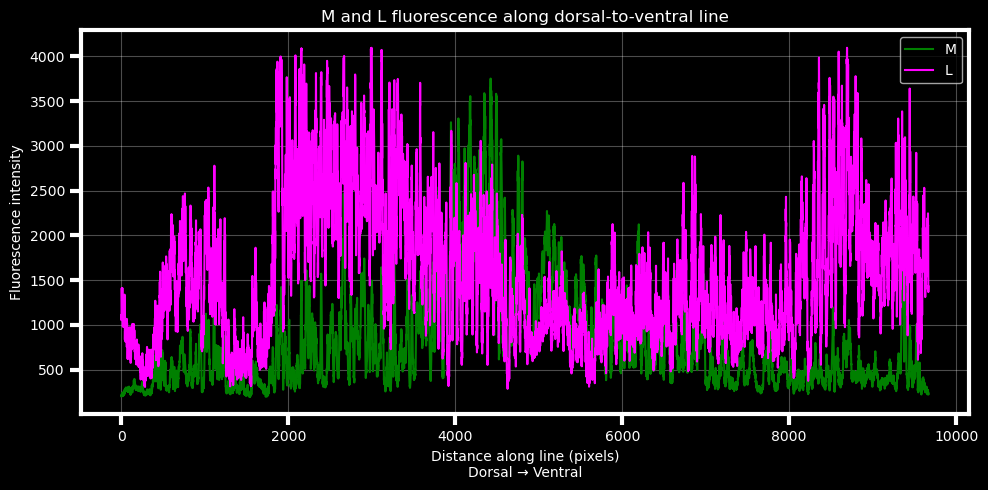

Plot path:
Z:/Analysis/20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO/mip_stitched/20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_001_mip_stitched\M_L_dorsal_to_ventral_intensity.png


In [61]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Image layers and plot colors
image_layer_names = ["M", "L"]
plot_colors = {
    "M": "green",
    "L": "magenta"
}

fig, ax = plt.subplots(figsize=(10, 5))

for image_layer_name in image_layer_names:
    profile_path = os.path.join(
        analysis_dir,
        f"{image_layer_name}_direction_profile.csv"
    )

    if not os.path.isfile(profile_path):
        raise FileNotFoundError(
            f"Could not find profile file:\n{profile_path}"
        )

    profile_table = pd.read_csv(profile_path)

    required_columns = {
        "distance_pixels",
        "intensity"
    }

    missing_columns = required_columns - set(profile_table.columns)

    if missing_columns:
        raise ValueError(
            f"{profile_path} is missing columns: {missing_columns}"
        )

    ax.plot(
        profile_table["distance_pixels"],
        profile_table["intensity"],
        color=plot_colors[image_layer_name],
        linewidth=1.5,
        label=image_layer_name
    )

    print(f"Loaded profile: {profile_path}")

ax.set_xlabel("Distance along line (pixels)\nDorsal → Ventral")
ax.set_ylabel("Fluorescence intensity")
ax.set_title("M and L fluorescence along dorsal-to-ventral line")
ax.legend()
ax.grid(True, alpha=0.3)

# Optional limits:
# ax.set_xlim([0, 4000])
# ax.set_ylim([0, 8000])

fig.tight_layout()

plot_path = os.path.join(
    analysis_dir,
    "M_L_dorsal_to_ventral_intensity.png"
)

# Uncomment to save the figure:
fig.savefig(plot_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Plot path:\n{plot_path}")

# Notes for analyzing across samples 

### Normalize across retinas bc size variance and need to compare 
> x axis is not in pixels, rather 0-1 in fractons (issue is one retina has more or less points)

1. linear interpolation
    1. np.interpolate 

#### z normalization and takes into account variance of data and range (search this and check what represents the population of data the best)

options 
1. normalize to max 
2. normalize to z score 
3. raw fluorescence (VERY UNLIKELY)

### instead of calculating avg in fractions, you can calculate based on bins (grouped on bins to give you an avg trace).

(Slightly easier to implement)

### Establish landmarks in whole-eye MIP
- Use eyeMarks layer to mark:
    - [ ] Landmark #1: Center of FOV (where zoom in is centered)
    - [ ] Landmark #2: Center of Optic Nerve Head 
    - [ ] Landmark #3: Dorsal edge of eye
    - [ ] Landmark #4: Ventral edge of eye
    - [ ] Landmark #5: Temporal edge of eye (strike zone side)
    - [ ] Landmark #6: Nasal edge of eye
- Decide if stack should be excluded (and stop analysis here and make note in csv summary file)

In [11]:
nMIP = len(layerNames)
for name in layerNames:
   lName = name + "_mip"
   viewer.layers[lName].scale = [1.5/8,1.5/8];
   viewer.layers[lName].translate = [0,+(512-1024*1.5/(8*2))]

# Load whole-eye MIP to establish landmarks
print('Loading eye mip...')
if str.endswith(filePath,'002'):
    mipPath = filePath[:-1] + '1_mip';
elif str.endswith(filePath,'004'):
    mipPath = filePath[:-1] + '3_mip';
elif str.endswith(filePath,'b'):
    mipPath = filePath[:-1] + 'a_mip';
elif str.endswith(filePath,'d'):
    mipPath = filePath[:-1] + 'c_mip';
viewer.open((dirData+mipPath + '.nd2'), plugin='napari-nikon-nd2', blending='additive')

viewer.layers.remove(viewer.layers[len(viewer.layers)-1]) # remove transmitted detector image
viewer.layers.select_next();
eyeChannels = 0
if len(viewer.layers)==2+nMIP+nChannels: # no DAPI, GFP and RFP
   eyeChannels = 2
   viewer.layers[nMIP+nChannels].colormap = 'green'
   viewer.layers[nMIP+nChannels].name = 'eyeGreen'
   viewer.layers[nMIP+nChannels+1].colormap = 'magenta'
   viewer.layers[nMIP+nChannels+1].name = 'eyeRed'
elif len(viewer.layers)==3+nMIP+nChannels: # leave DIC
   eyeChannels = 3
   viewer.layers[nMIP+nChannels+0].colormap = 'green'
   viewer.layers[nMIP+nChannels+0].name = 'eyeGreen'
   viewer.layers[nMIP+nChannels+1].colormap = 'magenta'
   viewer.layers[nMIP+nChannels+1].name = 'eyeRed'
   viewer.layers[nMIP+nChannels+2].colormap = 'gray'
   viewer.layers[nMIP+nChannels+2].name = 'eyeBlue'
   viewer.layers[nMIP+nChannels+2].opacity = 0.33
elif len(viewer.layers)==4+nMIP+nChannels: #DIC + DAPI
   eyeChannels = 4
   viewer.layers[nMIP+nChannels+0].colormap = 'gray'
   viewer.layers[nMIP+nChannels+0].name = 'eyeBlue'
   viewer.layers[nMIP+nChannels+1].colormap = 'green'
   viewer.layers[nMIP+nChannels+1].name = 'eyeGreen'
   viewer.layers[nMIP+nChannels+2].colormap = 'magenta'
   viewer.layers[nMIP+nChannels+2].name = 'eyeRed'
   viewer.layers[nMIP+nChannels+3].colormap = 'bop orange'
   viewer.layers[nMIP+nChannels+3].name = 'eyePNA'
   viewer.layers[nMIP+nChannels+3].opacity = 0.33
print(eyeChannels)
print('Loaded: ' + filePath)
eyeMarks = viewer.add_points(size=20, name = 'eyeMarks', symbol='cross', face_color='#ffffff80')
viewer.layers.select_next();

# Save eye landmarks
eyeMarksButton = ipywidgets.Button(description='Save eyeMarks', layout=ipywidgets.Layout(width='200px', height='100px'))
out = ipywidgets.Output()
def eyeMClick(_):
   with out:
      l = viewer.layers['eyeMarks']; l.save(dirOut + l.name + '.csv');
      print('eyeMarks layers saved for ' + filePath)
   # clear viewer
   viewer.layers.select_all()
   viewer.layers.remove_selected()
   eyeMarksButton.disabled = True # to prevent double clicking warnings. All sales are final!

eyeMarksButton.on_click(eyeMClick)

print('Make 6 landmark points then click button to save')

ipywidgets.VBox([eyeMarksButton,out])

Loading eye mip...


FileNotFoundError: [Errno 2] No such file or directory: 'Y:\\AxR\\20260212_tbx2bhetinx_tdT_m2G+Sideviews_5d\\20260212_5d_tbx2bhetinx_m2G_tdT_L01_002_Denoisec_mip.nd2'

### [Go back and run next one &uarr;](#zExtract)

***
## Quantification: GFP inside S cones<a id='quantification'>∮</a>
***
[Back to Index](#Index)

Plan (loosely based on Mander's coefficient):
1. Erode S cone segmentation to focus on center of cells
2. Divide GFP fluorescence into millies as a way to normalize data between images into 0 - 1000 range
3. Calculate for each cone what normalized average fluorescence corresponds too.

Questions:
1. How much erosion?
2. Do I have to exclude S cones to do GFP percentile calculation? &rarr; this would assume that GFP outside L cones is unchanged, which could be tested|plotted directly.
3. Also check if RFP distributions are unchanged?

In [26]:
erodeV = 10; #12;

# analysis directory
dAnalysis = "Z:/Analysis/20250829_tbx2ahetinx_s2Cm2G/s2Cm2G/"

# open file

# uninjected
### 20201009: imaged 3dpf and 5dpf larvae. Analyzing 5 dpf for paper
gene = '2ahetinx'
wt_fPaths = [
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L01_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L02_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L02_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L03_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L04_002',
# '20250829_5dpf_tbx2ahetinx_s2C_m2G_L05_002', #curved -OMIT? 
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L06_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L06_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L07_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L08_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L08_006', 
# '20250829_5dpf_tbx2ahetinx_s2C_m2G_L09_002', #curved
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L09_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L10_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L11_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L12_002',
# '20250829_5d_tbx2ahetinx_s2C_m2G_L13_002', #curved zoom in
'20250829_5d_tbx2ahetinx_s2C_m2G_L14_002',
'20250829_5d_tbx2ahetinx_s2C_m2G_L15_002'
         ]
for fPath in wt_fPaths:
    GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
    for l in viewer.layers:
        viewer.layers.remove(l)
#QUANTIFIED GFP IN THE SAMPLES WOOHOO 10/20/2025    
    
# # tbx2a
# gene = 'tbx2a';
# tbx2a_fPaths = [
#                ]
# for fPath in tbx2a_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)

# # tbx2b
# gene = 'tbx2b';
# tbx2b_fPaths = [
#                ]

# for fPath in tbx2b_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)

print('Finished analysis')

C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in S cones of 20250829_5dpf_tbx2ahetinx_s2C_m2G_L01_006(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in S cones of 20250829_5dpf_tbx2ahetinx_s2C_m2G_L02_002(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in S cones of 20250829_5dpf_tbx2ahetinx_s2C_m2G_L02_006(2ahetinx)



... (24 outputs left out)

C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in S cones of 20250829_5d_tbx2ahetinx_s2C_m2G_L15_002(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Finished analysis


In [13]:
erodeV = 10; #12;

# analysis directory
dAnalysis = "Z:/Analysis/20250817_tbx2ahetinx_m2G_tdT/m2GtdT/"

# open file

# uninjected
### 20201009: imaged 3dpf and 5dpf larvae. Analyzing 5 dpf for paper
gene = '2ahetinx'
wt_fPaths = [ '220250818_5d_2ahetinx_tdT_m2G_L01_002',
'220250818_5d_2ahetinx_tdT_m2G_L02_002',
'220250818_5d_2ahetinx_tdT_m2G_L03_002',
'220250818_5d_2ahetinx_tdT_m2G_L04_002',
 '220250818_5d_2ahetinx_tdT_m2G_L05_002',
'220250818_5d_2ahetinx_tdT_m2G_L05_004',
'220250818_5d_2ahetinx_tdT_m2G_L06_002',
'220250818_5d_2ahetinx_tdT_m2G_L07_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_004',
'220250818_5d_2ahetinx_tdT_m2G_L09_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_006',
'220250818_5d_2ahetinx_tdT_m2G_L010_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_006',
#'220250817_5d_m2G_tdT_2ahetinx_L12_002',
'220250817_5d_m2G_tdT_2ahetinx_L12_006',
'220250817_5d_m2G_tdT_2ahetinx_L13_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_006'
         ]
for fPath in wt_fPaths:
    GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
    for l in viewer.layers:
        viewer.layers.remove(l)
    
# # tbx2a
# gene = 'tbx2a';
# tbx2a_fPaths = ["20201009_5dpf_Rh22G_trb2T_CRtbx2a_i07b",
# #                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i07b",  # is this supposed to be d????
#                 # #### fPath = "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i08b", #very curved stack. would require oblique cut
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i08d",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i09b",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i09d",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i10b", #done; this could be example
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i10d",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i11b", #done; very clean L-cone seg
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i11d",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i12b",
#                 #### fPath = "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i12d", # this in lens up
#                ]
# for fPath in tbx2a_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)

# # tbx2b
# gene = 'tbx2b';
# tbx2b_fPaths = ["20201030_5dpf_Rh22G_trb2T_CRtbx2b_i07b",
#                 "20201030_5dpf_Rh22G_trb2T_CRtbx2b_i07d",
#                  "20201030_5dpf_Rh22G_trb2T_CRtbx2b_i08b",
#                 "20201030_5dpf_Rh22G_trb2T_CRtbx2b_i08d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L102b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L102d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L104b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L104d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L105b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L105d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L106b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L107b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L108b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L108d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L109b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L110b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L111b",
#                ]

# for fPath in tbx2b_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)

print('Finished analysis')


C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in L cones of 220250818_5d_2ahetinx_tdT_m2G_L01_002(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in L cones of 220250818_5d_2ahetinx_tdT_m2G_L02_002(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in L cones of 220250818_5d_2ahetinx_tdT_m2G_L03_002(2ahetinx)



... (30 outputs left out)

C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in L cones of 220250817_5d_m2G_tdT_2ahetinx_L14_006(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Finished analysis


### collect all results

GFP threshold is 0.215
# cells of bright GFP cells: wt=4.451990190530088, tbx2a=3.8421599169262723, tbx2b=2.3376623376623376


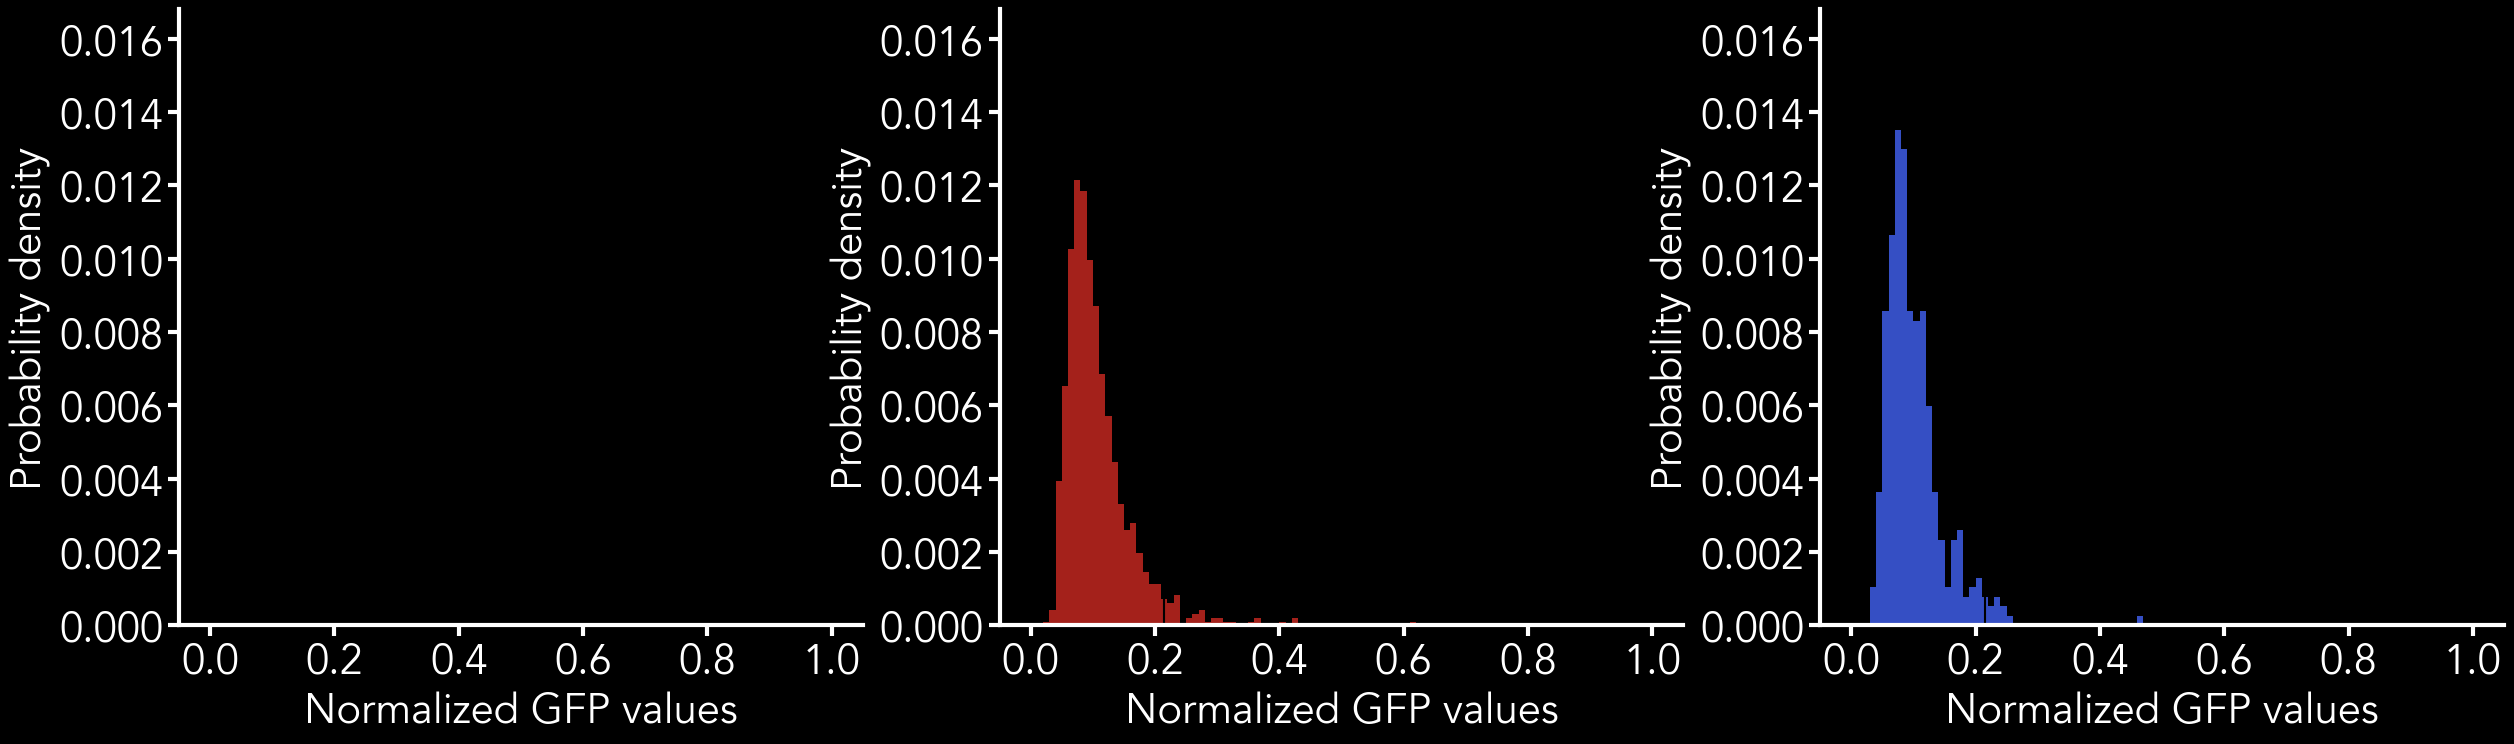

In [17]:
### After establishing threshold based on all data, count number of cells exceeding threshold for each eye# collect all results

# analysis directory
dAnalysis = "Z:/Analysis/20250817_tbx2ahetinx_m2G_tdT/m2GtdT/"

#OpenFile

# uninjected
### 20201009: imaged 3dpf and 5dpf larvae. Analyzing 5 dpf for paper
gene = '2ahetinx'
wt_fPaths = ['220250818_5d_2ahetinx_tdT_m2G_L01_002',
'220250818_5d_2ahetinx_tdT_m2G_L02_002',
'220250818_5d_2ahetinx_tdT_m2G_L03_002',
 '220250818_5d_2ahetinx_tdT_m2G_L05_002',
'220250818_5d_2ahetinx_tdT_m2G_L05_004',
'220250818_5d_2ahetinx_tdT_m2G_L06_002',
'220250818_5d_2ahetinx_tdT_m2G_L07_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_004',
'220250818_5d_2ahetinx_tdT_m2G_L010_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_006',
#'220250817_5d_m2G_tdT_2ahetinx_L12_002',
'220250817_5d_m2G_tdT_2ahetinx_L12_006',
'220250817_5d_m2G_tdT_2ahetinx_L13_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_006'
         ]
# tbx2a
gene = '2ahetinx';
tbx2a_fPaths = [
'220250818_5d_2ahetinx_tdT_m2G_L04_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_006'
               ]
# tbx2b
gene = '2ahetinx';
tbx2b_fPaths = ['220250818_5d_2ahetinx_tdT_m2G_L01_002',

               ]
                
                
rName = 'lGtile'

wtResults = []
i=1;
for fPath in wt_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
    wtResults.append(results[rName])
    i=i+1;

aResults = []
i=1;
for fPath in tbx2a_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
    aResults.append(results[rName])
    i=i+1;

bResults = []
i=1;
for fPath in tbx2b_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
    bResults.append(results[rName])
    i=i+1;


# combine across images
wtResults = np.concatenate(wtResults).ravel()
aResults = np.concatenate(aResults).ravel()
bResults = np.concatenate(bResults).ravel()

# plot histogram
pdfV = True
# wtH, wtB = np.histogram(wtResults, bins = 50, density=pdfV)
# aH, aB = np.histogram(aResults, bins = 50, density=pdfV)
# bH, bB = np.histogram(bResults, bins = 50, density=pdfV)

# plot histogram but first calculate a fixed bin number for all genotypes
# allBins = np.histogram_bin_edges(np.concatenate([wtResults,aResults,bResults]).ravel(),bins='fd');
allBins = np.arange(0,1010,10);
allBinsC = (allBins[:-1] + allBins[1:]) / 2 # Centers
wtH, wtB = np.histogram(wtResults, bins = allBins, density=pdfV)
aH, aB = np.histogram(aResults, bins = allBins, density=pdfV)
bH, bB = np.histogram(bResults, bins = allBins, density=pdfV)

# # this can be used for cumulative distribution then normalized
# wtH = np.cumsum(wtH)/np.max(np.cumsum(wtH));
# aH = np.cumsum(aH)/np.max(np.cumsum(aH));
# bH = np.cumsum(bH)/np.max(np.cumsum(bH));

wt95CI = np.min(allBinsC[(np.cumsum(wtH))>.095])/1000;
wGBright = np.sum(wtH[allBinsC>wt95CI*1000]);
aGBright = np.sum(aH[allBinsC>wt95CI*1000]);
bGBright = np.sum(bH[allBinsC>wt95CI*1000]);

print('GFP threshold is {0}'.format(wt95CI))


baseColor='#000000'
# fH, (axH1,axH2,axH3) = plt.subplots(nrows=3, ncols=1, figsize=(10, 20))
fH, (axH1,axH2,axH3) = plt.subplots(nrows=1, ncols=3, figsize=(30, 8))
axH1.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH2.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH3.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH2.stairs(aH,aB/1000, fill=True, color = zfC['lws1'], alpha = 0.8)
axH3.stairs(bH,bB/1000, fill=True, color = zfC['sws2'], alpha = 0.8)


axH1.plot([wt95CI,wt95CI],[0,0.016],color=baseColor)
axH2.plot([wt95CI,wt95CI],[0,0.016],color=baseColor)
axH3.plot([wt95CI,wt95CI],[0,0.016],color=baseColor)


# axH.set_title('Distribution of GFP inside L cones')
for axH in (axH1,axH2,axH3):
    formatFigureMain(fH, axH, _)
    axH.set_xlabel('Normalized GFP values')
    if pdfV:
        axH.set_ylabel('Probability density')
    else:
        axH.set_ylabel('Counts')
## normalized
# axH.stairs(wtH/np.max(wtH),wtB, fill=True, color = 'k', alpha = 0.5)
# axH.stairs(aH/np.max(aH),aB, fill=True, color = 'r', alpha = 0.5)
# axH.stairs(bH/np.max(bH),bB, fill=True, color = 'b', alpha = 0.5)

# plt.savefig(dPath + "CRtbx2F0_LM_hist.svg", transparent=True, format="svg")

print('# cells of bright GFP cells: wt={0}, tbx2a={1}, tbx2b={2}'.format(wGBright*1000,aGBright*1000,bGBright*1000))

In [ ]:

# fH, (axH1,axH2,axH3) = plt.subplots(nrows=3, ncols=1, figsize=(10, 20))
fH, axH = plt.subplots(nrows=1, ncols=1, figsize=(9, 6))


# plot histogram
pdfV = True
# wtH, wtB = np.histogram(wtResults, bins = 50, density=pdfV)
# aH, aB = np.histogram(aResults, bins = 50, density=pdfV)
# bH, bB = np.histogram(bResults, bins = 50, density=pdfV)

# plot histogram but first calculate a fixed bin number for all genotypes
# allBins = np.histogram_bin_edges(np.concatenate([wtResults,aResults,bResults]).ravel(),bins='fd');
allBins = np.arange(0,1010,10);
allBinsC = (allBins[:-1] + allBins[1:]) / 2 # Centers
wtH, wtB = np.histogram(wtResults, bins = allBins, density=pdfV)
aH, aB = np.histogram(aResults, bins = allBins, density=pdfV)
bH, bB = np.histogram(bResults, bins = allBins, density=pdfV)

# # this can be used for cumulative distribution then normalized
# wtH = np.cumsum(wtH)/np.max(np.cumsum(wtH));
# aH = np.cumsum(aH)/np.max(np.cumsum(aH));
# bH = np.cumsum(bH)/np.max(np.cumsum(bH));

wt95CI = np.min(allBinsC[(np.cumsum(wtH))>.095])/1000;
wGBright = np.sum(wtH[allBinsC>wt95CI*1000]);
aGBright = np.sum(aH[allBinsC>wt95CI*1000]);
bGBright = np.sum(bH[allBinsC>wt95CI*1000]);


axH.stairs(wtH,wtB/1000, fill=True, color = 'k', alpha = .5)
axH.stairs(aH,aB/1000, fill=True, color = zfC['lws1'], alpha = .5)
axH.stairs(bH,bB/1000, fill=True, color = zfC['sws2'], alpha = .5)


axH.plot([wt95CI,wt95CI],[0,0.016],color=baseColor)

formatFigureMain(fH, axH, _)
# axH.set_title('Distribution of GFP inside L cones')
axH.set_xlabel('Normalized GFP values')
if pdfV:
    axH.set_ylabel('Probability density')
else:
    axH.set_ylabel('Counts')
## normalized
# axH.stairs(wtH/np.max(wtH),wtB, fill=True, color = 'k', alpha = 0.5)
# axH.stairs(aH/np.max(aH),aB, fill=True, color = 'r', alpha = 0.5)
# axH.stairs(bH/np.max(bH),bB, fill=True, color = 'b', alpha = 0.5)

# dPath = '/Users/angueyraaristjm/Documents/LiLab/Manuscripts/2021_zfConeRNAseq/resources/'
dPath = '/Users/angueyraaristjm/Documents/LiLab/Conferences/2021_RCS/resources/'
# plt.savefig(dPath + "CRtbx2F0_LM_hist.svg", transparent=True, format="svg")

print('# cells of bright GFP cells: wt={0}, tbx2a={1}, tbx2b={2}'.format(wGBright*1000,aGBright*1000,bGBright*1000))

### After establishing threshold based on all data, count number of cells exceeding threshold for each eye

Threshold (5%) is 0.215


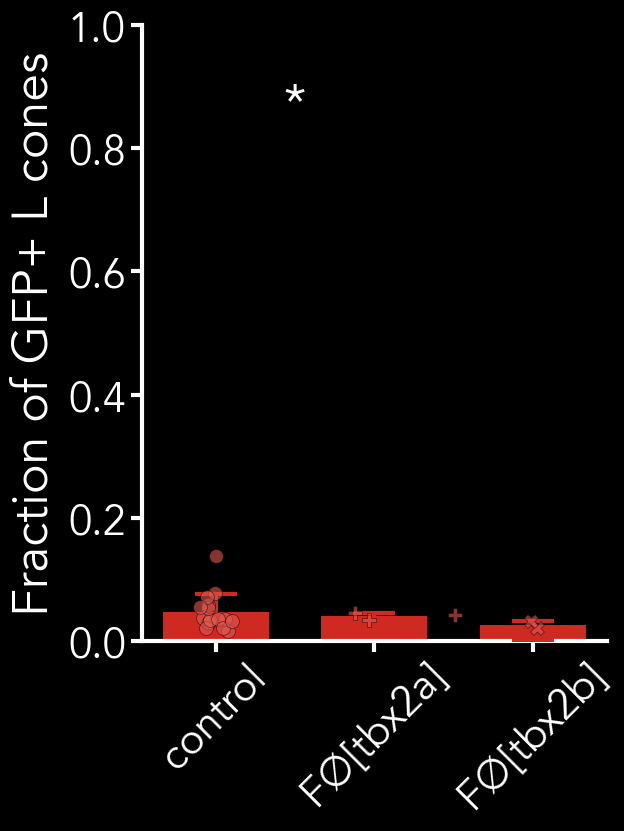

In [19]:
# collect all results

# analysis directory
dAnalysis =  "Z:/Analysis/20250817_tbx2ahetinx_m2G_tdT/m2GtdT/"
# open file

# uninjected
### 20201009: imaged 3dpf and 5dpf larvae. Analyzing 5 dpf for paper
gene = '2ahetinx'
wt_fPaths = ['220250818_5d_2ahetinx_tdT_m2G_L01_002',
'220250818_5d_2ahetinx_tdT_m2G_L02_002',
'220250818_5d_2ahetinx_tdT_m2G_L03_002',
 '220250818_5d_2ahetinx_tdT_m2G_L05_002',
'220250818_5d_2ahetinx_tdT_m2G_L05_004',
'220250818_5d_2ahetinx_tdT_m2G_L06_002',
'220250818_5d_2ahetinx_tdT_m2G_L07_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_004',
'220250818_5d_2ahetinx_tdT_m2G_L010_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_006',
#'220250817_5d_m2G_tdT_2ahetinx_L12_002',
'220250817_5d_m2G_tdT_2ahetinx_L12_006',
'220250817_5d_m2G_tdT_2ahetinx_L13_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_006'
         ]
# tbx2a
gene = '2ahetinx';
tbx2a_fPaths = ['220250818_5d_2ahetinx_tdT_m2G_L04_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_006'
               ]
# tbx2b
gene = 'tbx2b';
tbx2b_fPaths = ['220250817_5d_m2G_tdT_2ahetinx_L14_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_006'
               ]
                
rName = 'lGtile'

wtResults = []
i=1;
for fPath in wt_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
#     wtResults.append(np.count_nonzero(results['lGtile']>wt95CI*1000)) #this is for absolute counts
    wtResults.append(np.divide(np.count_nonzero(results['lGtile']>wt95CI*1000),len(results['lGtile']))) #this is for fraction
    i=i+1;

    
aResults = []
i=1;
for fPath in tbx2a_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
#     aResults.append(np.count_nonzero(results['lGtile']>wt95CI*1000)) #this is for absolute counts
    aResults.append(np.divide(np.count_nonzero(results['lGtile']>wt95CI*1000),len(results['lGtile']))) #this is for fraction
    i=i+1;

bResults = []
i=1;
for fPath in tbx2b_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
#     bResults.append(np.count_nonzero(results['lGtile']>wt95CI*1000)) #this is for absolute counts
    bResults.append(np.divide(np.count_nonzero(results['lGtile']>wt95CI*1000),len(results['lGtile']))) #this is for fraction
    i=i+1;

# geneList = ['2ahetinx','tbx2a','tbx2b']

geneList = ['2ahetinx']

plotname = ''
fH, axH = plt.subplots(figsize= [6,8])

barW = np.size(geneList)+2; # bar width
barD = np.size(geneList)+1; # bar distance whitin 1 photoreceptor subtype
barP = -np.size(geneList)+1; # position in x-axis
barStep = 0.9; # distance between photoreceptor groups
barPos = []; #array to save bar positions


jitter = estimateJitter(wtResults)/400
pH = plt.bar([barStep+1/barD], np.mean(wtResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+1/barD], np.mean(wtResults), yerr = [[0.025],[np.std(wtResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(wtResults))*[barStep+1/barD]+jitter, wtResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['wt'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+1/barD))



jitter = estimateJitter(aResults)/400
pH = plt.bar([barStep+2/barD], np.mean(aResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+2/barD], np.mean(aResults), yerr = [[0.025],[np.std(aResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(aResults))*[barStep+2/barD]+jitter, aResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['tbx2a'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+2/barD))

jitter = estimateJitter(bResults)/400
pH = plt.bar([barStep+3/barD], np.mean(bResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+3/barD], np.mean(bResults), yerr = [[0.025],[np.std(bResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(bResults))*[barStep+3/barD]+jitter, bResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['tbx2b'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+3/barD))

fontProps = formatFigureMain(fH, axH, pH)

# axH.set_ylabel('GFP+ L cones per 64 x 64 $\mu$m$^2$', fontproperties=formatFigureMain(fH, axH, pH))
# axH.set_ylim([0,180]);
# stath = 170

axH.set_ylabel('Fraction of GFP+ L cones', fontproperties=fontProps)
axH.set_ylim([0,1]);
stath = 0.85

geneList = ['control','F$\emptyset$[tbx2a]','F$\emptyset$[tbx2b]']

axH.xaxis.set_tick_params(rotation=45)
axH.set_xticks(np.sort(barPos));
axH.set_xticklabels(geneList);

hH = plt.hlines(stath, barPos[0], barPos[1], colors='#000000',linewidth=4)
plt.text((barPos[0]+barPos[1])/2, stath, '*', font_properties=fontProps, fontsize=36, ha='center')# plt.savefig(savePath + "Counts_tbx2_RU.svg", transparent=True, format="svg")


dPath = '/Users/angueyraaristjm/OneDrive - National Institutes of Health/zf/Manuscripts/2021_zfConeRNAseq/resources/'
# dPath = '/Users/angueyraaristjm/Documents/LiLab/Presentations/revealjs/resources/20211008_UCLA/'
# plt.savefig(dPath + "CRtbx2F0_GFPLcones.svg", transparent=True, format="svg")

print('Threshold (5%) is {0}'.format(wt95CI))

### Load segmentaion file (TIFF) and extract data to save as  NUMPY Array 

In [27]:

# Import libraries
import numpy as np
from skimage import measure, io
from skimage.measure import regionprops


dirData = 'Z:/AxR/20260610_4Month_Tbx2a_m2G_s2C_Cryosections/'
# define where all the analysis files should be stored
# subdirectories for each gene and transgenic lines need to be manually made first
dirAnalysis =  "Z:/Analysis/20260610_4Month_Tbx2aAdult_m2G_s2C_Cryosections/"



# DEFINE List of layer names
# layerNames = ['M', 'S', 'PNA', 'N']
# layerNames = ['R', 'U','PNA', 'N']
# layerNames = ['M', 'L', 'L_misexpressing']
layerNames = ['M', 'S', 'PNA']
# layerNames = ['N', 'U']


# clear viewer before any loading
viewer.layers.select_all()
viewer.layers.remove_selected()

## Load Segmentation files: 

# Zoom Out [001] 
# filePath = '20260610_0yr4mo_tbx2aKO_m2G_s2C_Cryo_L01_S01_001_mip_stitched'; gene = 'mip_stitched'; 
# filePath = '20260610_0yr4mo_tbx2aKO_m2G_s2C_Cryo_L01_S04_001_mip_stitched'; gene = 'mip_stitched'; #optic nerve in - good example? 
# filePath = '20260610_0yr4mo_tbx2aKO_m2G_s2C_Cryo_L02_S01_001mip_stitched'; gene = 'mip_stitched'; 
# filePath = '20260610_4Mo_Tbx2aHET_m2G_s2C_Cry_L02_S01_001_mip_stitched'; gene = 'mip_stitched'; 

#Dorsal zoom in [002] 

# filePath = '20260610_0yr4mo_tbx2aKO_m2G_s2C_Cryo_L01_S04_002'; gene = ''; zlims = [1, 2]; #segmented S only - no M bc 2a KO (M unreliable)
filePath = '20260610_4Mo_Tbx2aHET_m2G_s2C_Cry_L02_S01_002'; gene = ''; zlims = [5, 6];

# Ventral Cones [003] - comeback for misexpression in ventral retina

# filePath = '20260610_0yr4mo_tbx2aKO_m2G_s2C_Cryo_L01_S04_003'; gene = '';  zlims = [5, 6];


# load mips
mipO = 0.65
viewer.open(dirAnalysis + filePath + '/' + layerNames[0] + "_mip.tiff", plugin='napari', colormap = 'green', blending='additive', opacity=mipO);
viewer.open(dirAnalysis + filePath + '/' +  layerNames[1] + "_mip.tiff", plugin='napari', colormap = 'magenta', blending='additive', opacity=mipO);

print("Loaded mip")

# Load Segmentation TIFF 
# viewer.open(dirAnalysis + filePath + '/' + layerNames[0] + "_seg_curated.tif", plugin='napari', colormap = 'green', blending='additive', opacity=mipO);
# viewer.open(dirAnalysis + filePath + '/' + layerNames[1] + "_seg_curated.tif", plugin='napari', colormap = 'magenta', blending='additive', opacity=mipO);


# print("Loaded Segmentation TIFF")

# dirOut = dirAnalysis + filePath + '/' 

# #Code for turning to numpy array 

# lname_0 = layerNames[0] + '_seg_curated'
# lname_1 = layerNames[1] + '_seg_curated'
# # lname_2 = layerNames[2] + '_seg_curated'

# # Access the data from the Napari layer
# layer0_data = viewer.layers[lname_0].data
# layer1_data = viewer.layers[lname_1].data
# # layer2_data = viewer.layers[lname_2].data


# # Save the data as a NumPy array with filenames reflecting the layer
# np.save(dirOut + layerNames[0] + '_seg_curated.npy', layer0_data)
# print(f'Saved {layerNames[0]}_seg_curated as NumPy array.')

# np.save(dirOut + layerNames[1] + '_seg_curated.npy', layer1_data)
# print(f'Saved {layerNames[1]}_seg_curated as NumPy array.')

# np.save(dirOut + layerNames[2] + '_seg_curated.npy', layer1_data)
# print(f'Saved {layerNames[2]}_seg_curated as NumPy array.')


Loaded mip


## Code to save the numpy array for 3 segmentation files (L, M, L-misexpressing)

In [100]:
import os
from pathlib import Path
import numpy as np
import tifffile

# Clear the Napari viewer
viewer.layers.select_all()
viewer.layers.remove_selected()

# Base directories
dirAnalysis = Path(
    r"Z:\Analysis\20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO"
)

# Select the dataset

#Dorsal zoom in [002] - HET 
# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L01_S01_002'; gene = ''; zlims = [6, 7]; #Piezo wasn't on - oops 

#Dorsal zoom in [002] - KO  
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_002'; gene = ''; zlims = [0, 1]; # cannot confidently segment single-positive GFP cells, misexpressing L cones = 1, 2, 3, 4, 7, 8, 9, 10
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_003'; gene = ''; zlims = [0, 1]; #2nd dorsal zoom in on same slice (need to choose) - SINCE THIS IS FURTHER OUT - omit 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S02_002'; gene = ''; zlims = [0, 1]; #single positive = 1-3, Co-labelled = - issue is the pedicles do not show co-expression but the cell bodies do. 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S02_003'; gene = ''; zlims = [3, 4]; #misexpressing l (n=3),Single L (n=2), single M (n=3)
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_002'; gene = ''; zlims = [0, 1]; #use this as an example!!! #very little co-expressing L cones in this example lots of single positive. Single positive L = 1-7#saved seaprate seg file for misexpressing L cones (n =2), Single M (n=10), single L (n=9) 

# Ventral Cones [003] - comeback for misexpression in ventral retina
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_003'; gene = ''; zlims = [0, 1]; #Single L (n=2), Single M (n=2), Misexpressing l (n=1)
filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_004'; gene = ''; zlims = [0, 1]; #all gfp inside the l cones here - very cool. Mis-expressing L (n=8), single-positive L (n=4), no mws2 single positive. 
# filePath = '20260610_4Mo_Tbx2aKO_m2G_tdT_L02_S01_004'; gene = ''; zlims = [0, 1]; #GFP does not localize correctly here. COMEBACK

# filePath = '20260610_4Mo_Tbx2aHET_m2G_tdT_L01_S01_003'; gene = ''; zlims = [0, 1]; #no mis-expressing L cones


dirOut = dirAnalysis / filePath

# Display settings
mip_opacity = 0.65
seg_opacity = 0.65

# Files to load: filename, Napari layer name, colormap, layer type
files_to_load = [
    ("M_mip.tiff", "M", "green", "image"),
    ("L_mip.tiff", "L", "magenta", "image"),
    ("PNA_mip.tiff", "PNA", "bop orange", "image"),
    # ("M_seg_curated.tif", "M_seg_curated", "green", "segmentation"),
    ("L_seg_curated.tif", "L_seg_curated", "magenta", "segmentation"),
    (
        "L_misexpressing_seg_curated.tif",
        "L_misexpressing_seg_curated",
        "bop orange",
        "segmentation",
    ),
]

# Verify that every expected file exists before changing the viewer further
missing_files = [
    str(dirOut / filename)
    for filename, _, _, _ in files_to_load
    if not (dirOut / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(
        "The following expected files were not found:\n" +
        "\n".join(missing_files)
    )

# Load each file directly and assign the desired Napari layer name
loaded_layers = {}

for filename, layer_name, colormap, layer_type in files_to_load:
    file_path = dirOut / filename
    data = tifffile.imread(str(file_path))

    if layer_type == "segmentation":
        layer = viewer.add_image(
            data,
            name=layer_name,
            colormap=colormap,
            blending="additive",
            opacity=seg_opacity,
            interpolation="nearest",
        )
    else:
        layer = viewer.add_image(
            data,
            name=layer_name,
            colormap=colormap,
            blending="additive",
            opacity=mip_opacity,
            interpolation="nearest",
        )

    loaded_layers[layer_name] = layer
    print(f"Loaded {layer_name}: {filename}; shape={data.shape}")

# Retrieve the segmentation arrays for downstream analysis
# layer0_data = loaded_layers["M_seg_curated"].data
layer1_data = loaded_layers["L_seg_curated"].data
layer2_data = loaded_layers["L_misexpressing_seg_curated"].data

# Save segmentation arrays as NumPy files
# np.save(dirOut / "M_seg_curated.npy", layer0_data)
np.save(dirOut / "L_seg_curated.npy", layer1_data)
np.save(dirOut / "L_misexpressing_seg_curated.npy", layer2_data)

print("\nImages and curated segmentations loaded successfully.")
print("Napari layers:", [layer.name for layer in viewer.layers])
print(f"Saved NumPy arrays in: {dirOut}")


C:\Users\Carin\AppData\Local\Temp\ipykernel_41772\863878326.py:84: DeprecationWarning: Argument interpolation is deprecated, please use interpolation2d instead. It will be removed in 0.6.0.
  layer = viewer.add_image(


Loaded M: M_mip.tiff; shape=(1024, 2048)


C:\Users\Carin\AppData\Local\Temp\ipykernel_41772\863878326.py:84: DeprecationWarning: Argument interpolation is deprecated, please use interpolation2d instead. It will be removed in 0.6.0.
  layer = viewer.add_image(
C:\Users\Carin\AppData\Local\Temp\ipykernel_41772\863878326.py:84: DeprecationWarning: Argument interpolation is deprecated, please use interpolation2d instead. It will be removed in 0.6.0.
  layer = viewer.add_image(


Loaded L: L_mip.tiff; shape=(1024, 2048)
Loaded PNA: PNA_mip.tiff; shape=(1024, 2048)


C:\Users\Carin\AppData\Local\Temp\ipykernel_41772\863878326.py:75: DeprecationWarning: Argument interpolation is deprecated, please use interpolation2d instead. It will be removed in 0.6.0.
  layer = viewer.add_image(


Loaded L_seg_curated: L_seg_curated.tif; shape=(1024, 2048)


C:\Users\Carin\AppData\Local\Temp\ipykernel_41772\863878326.py:75: DeprecationWarning: Argument interpolation is deprecated, please use interpolation2d instead. It will be removed in 0.6.0.
  layer = viewer.add_image(


Loaded L_misexpressing_seg_curated: L_misexpressing_seg_curated.tif; shape=(1024, 2048)

Images and curated segmentations loaded successfully.
Napari layers: ['M', 'L', 'PNA', 'L_seg_curated', 'L_misexpressing_seg_curated']
Saved NumPy arrays in: Z:\Analysis\20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO\20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_004


### Calculate Cell Length 

In [102]:
## Calculate cell length and width using Scikit-Image 


# # # Calculate pixel spacing (dimensions from ND2 files)
# x_pixel_spacing = 238.9 / 2048  # microns per pixel -
# y_pixel_spacing = 119.45 / 1024  # microns per pixel
        
# # Calculate pixel spacing (dimensions from ND2 files) - Larval zoom in (9)
# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 40 / 1024  # microns per pixel

# Calculate pixel spacing (dimensions from ND2 files) - Cryosection zoom in (3) !!!!!!!
x_pixel_spacing = 238.9 / 2048  # microns per pixel -
y_pixel_spacing = 119.45 / 1024  # microns per pixel

# x_pixel_spacing = 83 / 1024  # microns per pixel
# y_pixel_spacing = 37 / 486  # microns per pixel

# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 80 / 2048  # microns per pixel

# layerNames = ['R', 'U','PNA', 'N']
# layerNames = ['M', 'L', 'PNA']
layerNames = ['M', 'L', 'L_misexpressing']

# # Calculate cell lengths using regionprops - RODS ONLY 
# for i, layer_data in enumerate([layer0_data]):
#     props = measure.regionprops(layer_data)
#     print(f"Cell lengths for {layerNames[i]} (in microns):")
#     for prop in props:
#         # Assuming measurements are along the major axis in the XY plane
#         length_in_microns = prop.major_axis_length * x_pixel_spacing  # or y_pixel_spacing if needed
#         print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns")

# # Calculate cell lengths using regionprops - UV ONLY 
# for i, layer_data in enumerate([layer1_data], start=1):
#     props = measure.regionprops(layer_data)
#     print(f"Cell lengths for {layerNames[i]} (in microns):")
#     for prop in props:
#         # Assuming measurements are along the major axis in the XY plane
#         length_in_microns = prop.major_axis_length * x_pixel_spacing  # or y_pixel_spacing if needed
#         print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns")


# Calculate cell lengths using regionprops - USE FOR BOTH M AND L SEGMENTATION 
for i, layer_data in enumerate([layer1_data, layer2_data], start=1):
    props = measure.regionprops(layer_data.astype(np.int32))
    print(f"Cell lengths for {layerNames[i]} (in microns):")
    for prop in props:
        # Assuming measurements are along the major axis in the XY plane
        length_in_microns = prop.major_axis_length * x_pixel_spacing  # or y_pixel_spacing if needed
        print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns")
        
        
# # Calculate cell lengths using regionprops - USE FOR BOTH M, L, L-MISEXPRESSING SEGMENTATION 
# for i, layer_data in enumerate([layer0_data, layer1_data, layer2_data]):
#     props = measure.regionprops(layer_data.astype(np.int32))
#     print(f"Cell lengths for {layerNames[i]} (in microns):")
#     for prop in props:
#         # Assuming measurements are along the major axis in the XY plane
#         length_in_microns = prop.major_axis_length * x_pixel_spacing  # or y_pixel_spacing if needed
#         print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns")


Cell lengths for L (in microns):
 - Cell ID 1: Length = 58.03 microns
 - Cell ID 2: Length = 49.63 microns
 - Cell ID 3: Length = 50.92 microns
 - Cell ID 4: Length = 53.35 microns
Cell lengths for L_misexpressing (in microns):
 - Cell ID 1: Length = 58.38 microns
 - Cell ID 2: Length = 55.37 microns
 - Cell ID 3: Length = 57.48 microns
 - Cell ID 4: Length = 52.55 microns
 - Cell ID 5: Length = 60.92 microns
 - Cell ID 6: Length = 64.29 microns
 - Cell ID 7: Length = 55.97 microns
 - Cell ID 8: Length = 50.27 microns


### Calculate Cell Width

In [103]:
# Calculate pixel spacing - RODS ONLY 
# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 40 / 1024  # microns per pixel


# Calculate pixel spacing - UV AND RODS 
# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 40 / 1024  # microns per pixel

# Calculate pixel spacing (dimensions from ND2 files) - Cryosection zoom in (3)
x_pixel_spacing = 238.9 / 2048  # microns per pixel -
y_pixel_spacing = 119.45 / 1024  # microns per pixel

# x_pixel_spacing = 83 / 1024  # microns per pixel
# y_pixel_spacing = 37 / 486  # microns per pixel

# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 80 / 2048  # microns per pixel

# Calculate cell widths (minor axis length) using regionprops ### UV AND RODS 
for i, layer_data in enumerate([layer1_data, layer2_data], start=1):
    props = measure.regionprops(layer_data)
    print(f"Cell dimensions for {layerNames[i]} (in microns):")
    for prop in props:
        # Calculate length and width in microns
        length_in_microns = prop.major_axis_length * x_pixel_spacing  # Assuming major axis aligns with X
        width_in_microns = prop.minor_axis_length * y_pixel_spacing   # Assuming minor axis aligns with Y
        print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns, Width = {width_in_microns:.2f} microns")
        
 # # Calculate cell widths (minor axis length) using regionprops - RODS ONLY!!!! 
# for i, layer_data in enumerate([layer0_data]):
#     props = measure.regionprops(layer_data)
#     print(f"Cell dimensions for {layerNames[i]} (in microns):")
#     for prop in props:
#         # Calculate length and width in microns
#         length_in_microns = prop.major_axis_length * x_pixel_spacing  # Assuming major axis aligns with X
#         width_in_microns = prop.minor_axis_length * y_pixel_spacing   # Assuming minor axis aligns with Y
#         print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns, Width = {width_in_microns:.2f} microns")

#  # # Calculate cell widths (minor axis length) using regionprops - UV ONLY!!!! 
# for i, layer_data in enumerate([layer1_data], start=1):
#     props = measure.regionprops(layer_data)
#     print(f"Cell dimensions for {layerNames[i]} (in microns):")
#     for prop in props:
#         # Calculate length and width in microns
#         length_in_microns = prop.major_axis_length * x_pixel_spacing  # Assuming major axis aligns with X
#         width_in_microns = prop.minor_axis_length * y_pixel_spacing   # Assuming minor axis aligns with Y
#         print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns, Width = {width_in_microns:.2f} microns")

# # Calculate cell widths (minor axis length) using regionprops ### L, M, L-misexpressing
# for i, layer_data in enumerate([layer0_data, layer1_data, layer2_data]):
#     props = measure.regionprops(layer_data)
#     print(f"Cell dimensions for {layerNames[i]} (in microns):")
#     for prop in props:
#         # Calculate length and width in microns
#         length_in_microns = prop.major_axis_length * x_pixel_spacing  # Assuming major axis aligns with X
#         width_in_microns = prop.minor_axis_length * y_pixel_spacing   # Assuming minor axis aligns with Y
#         print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns, Width = {width_in_microns:.2f} microns")


Cell dimensions for L (in microns):
 - Cell ID 1: Length = 58.03 microns, Width = 8.57 microns
 - Cell ID 2: Length = 49.63 microns, Width = 9.12 microns
 - Cell ID 3: Length = 50.92 microns, Width = 4.49 microns
 - Cell ID 4: Length = 53.35 microns, Width = 6.73 microns
Cell dimensions for L_misexpressing (in microns):
 - Cell ID 1: Length = 58.38 microns, Width = 8.10 microns
 - Cell ID 2: Length = 55.37 microns, Width = 4.15 microns
 - Cell ID 3: Length = 57.48 microns, Width = 6.67 microns
 - Cell ID 4: Length = 52.55 microns, Width = 8.71 microns
 - Cell ID 5: Length = 60.92 microns, Width = 5.62 microns
 - Cell ID 6: Length = 64.29 microns, Width = 8.98 microns
 - Cell ID 7: Length = 55.97 microns, Width = 14.52 microns
 - Cell ID 8: Length = 50.27 microns, Width = 9.67 microns


In [105]:
import numpy as np
from skimage import io, measure
import pandas as pd

# Define pixel spacing Cryosection zoom in (3)
x_pixel_spacing = 238.9 / 2048  # microns per pixel -
y_pixel_spacing = 119.45 / 1024  # microns per pixe

# x_pixel_spacing = 102 / 512  # microns per pixel
# y_pixel_spacing = 51 / 256  # microns per pixel

# x_pixel_spacing = 83 / 1024  # microns per pixel
# y_pixel_spacing = 37 / 486  # microns per pixel

# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 80 / 2048  # microns per pixel

# Prepare a list to store data
data = []


# Calculate cell dimensions and store them [UV AND RODS]
for i, layer_data in enumerate([layer1_data, layer2_data], start=1):
    props = measure.regionprops(layer_data)
    layer_name = layerNames[i]
    for prop in props:
        length_in_microns = prop.major_axis_length * x_pixel_spacing
        width_in_microns = prop.minor_axis_length * y_pixel_spacing
        data.append({
            'Layer': layer_name,
            'Cell ID': prop.label,
            'Length (microns)': length_in_microns,
            'Width (microns)': width_in_microns
        })


# # Calculate cell dimensions and store them [UV ONLY]
# for i, layer_data in enumerate([layer1_data], start=1):
#     props = measure.regionprops(layer_data)
#     layer_name = layerNames[i]
#     for prop in props:
#         length_in_microns = prop.major_axis_length * x_pixel_spacing
#         width_in_microns = prop.minor_axis_length * y_pixel_spacing
#         data.append({
#             'Layer': layer_name,
#             'Cell ID': prop.label,
#             'Length (microns)': length_in_microns,
#             'Width (microns)': width_in_microns
#         })


# # Calculate cell dimensions and store them [RODS ONLY]
# for i, layer_data in enumerate([layer0_data]):
#     props = measure.regionprops(layer_data)
#     layer_name = layerNames[i]
#     for prop in props:
#         length_in_microns = prop.major_axis_length * x_pixel_spacing
#         width_in_microns = prop.minor_axis_length * y_pixel_spacing
#         data.append({
#             'Layer': layer_name,
#             'Cell ID': prop.label,
#             'Length (microns)': length_in_microns,
#             'Width (microns)': width_in_microns
#         })

# # Calculate cell dimensions and store them [L, M, L-Misexpressing]
# for i, layer_data in enumerate([layer0_data, layer1_data, layer2_data]):
#     props = measure.regionprops(layer_data)
#     layer_name = layerNames[i]
#     for prop in props:
#         length_in_microns = prop.major_axis_length * x_pixel_spacing
#         width_in_microns = prop.minor_axis_length * y_pixel_spacing
#         data.append({
#             'Layer': layer_name,
#             'Cell ID': prop.label,
#             'Length (microns)': length_in_microns,
#             'Width (microns)': width_in_microns
#         })

# Convert to DataFrame
df = pd.DataFrame(data)

# Define the output file path
csv_file_path = dirOut / 'cell_dimensions.csv' #use for mixexpressing cells 

# csv_file_path = dirOut + 'cell_dimensions.csv' #use for 2 PR 

# Write to CSV
df.to_csv(csv_file_path, index=False)

print(f"Cell dimensions saved to {csv_file_path}")

Cell dimensions saved to Z:\Analysis\20260610_Tbx2aAdult_Cryosections_tdT_m2G_4months_CRYO\20260610_4Mo_Tbx2aKO_m2G_tdT_L01_S01_004\cell_dimensions.csv
